# Encoder fine-tuning as a defense, and a fair ranking of defenses

**Part A — Fair ranking.** The global-tile defense was tested with the *strong* adaptive attack; random resize-pad (the best whole-image defense) only with the weak one. Here random resize-pad gets the same strong attack: exact forward through the real processor, gradients through a differentiable copy, 2 random draws per step, 6 epochs, warm start from its weak adaptive v.

**Part B — Training-time defense: fine-tune SmolVLM's vision encoder** (93M of 256M parameters; the language model is untouched). Two variants:
- **FT-fixed** (what the original UAP paper did): fine-tune on images perturbed with the *fixed* v from notebook 01.
- **FT-UAT** (universal adversarial training, Shafahi et al. 2020): v is updated at every step while the encoder learns to resist it, so the encoder sees an evolving attacker.

Both use a **feature-anchoring loss**: the encoder's tokens for perturbed *and* clean images must stay close to the **original** encoder's tokens on the clean image. This keeps the encoder compatible with the language model, which was trained on the original features.

Each fine-tuned encoder is then attacked by an **adaptive v**: a new UAP computed against the fine-tuned encoder (same recipe as notebook 01, 7 epochs).

Everything is on 200 held-out images (splitting off), with 95% intervals, at the validated threshold 0.5 and the 0.7 sensitivity threshold. Every stage is saved and resumable.

**Rough estimate:** about 2 h in total. **Outputs:** the results of Part A (section 5) and Part B (sections 6, 7 and 9), plus the ranking figure `defense_ranking.png`.

## 1. Configuration

In [10]:
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
N_BUILD    = 500
N_EVAL     = 200
OUT_DIR    = "/content/drive/MyDrive/uap_smolvlm"
XI         = 10/255
V10_PATH   = OUT_DIR + "/uap_smolvlm256m_linf10.npy"
RRP_WEAK_PATH = OUT_DIR + "/adaptive_v10_random_resize_pad.npy"
# Part A
RRP_STRONG_CKPT = OUT_DIR + "/strong_adaptive_rrp_ckpt.pt"
RRP_EPOCHS = 8; EOT_DRAWS = 2; RRP_BATCH = 8; RRP_MIN = 0.8
# Part B
FT_EPOCHS  = 3
FT_LR      = 1e-5            # encoder learning rate
FT_BATCH   = 8
ANCHOR_W   = 1.0             # weight of the clean-image anchoring term
ADAPT_EPOCHS = 7             # adaptive UAP against each fine-tuned encoder (same recipe as notebook 01)
THRESHOLDS = [0.5, 0.7]      # 0.5 = validated main threshold; 0.7 = sensitivity check
MAX_NEW_TOKENS = 40
P_DESCRIBE = "Describe this image in one sentence."
SEED = 0

## 2. Setup, data, model

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile, math, copy
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
load = lambda fs: torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(fs, desc="decoding")])
B_u8 = load([FILES[i] for i in perm[:N_BUILD]])
E_u8 = load([FILES[i] for i in perm[N_BUILD:N_BUILD + N_EVAL]])

from transformers import AutoProcessor, AutoModelForImageTextToText
processor = AutoProcessor.from_pretrained(MODEL_ID); processor.tokenizer.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
for p in model.parameters(): p.requires_grad_(False)
VIS = model.model.vision_model
VIS0 = copy.deepcopy(VIS).eval()                       # frozen copy of the ORIGINAL encoder
for p in VIS0.parameters(): p.requires_grad_(False)
ip = processor.image_processor
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)
V10 = torch.from_numpy(np.load(V10_PATH).copy()).float()
RRP_WEAK = torch.from_numpy(np.load(RRP_WEAK_PATH).copy()).float()

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def sims(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu().numpy()
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G  84.7MB/s    in 18s     


/tmp/ipykernel_338/3911233932.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/500 [00:00<?, ?it/s]

decoding:   0%|          | 0/200 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

... (22 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Shared helpers

In [3]:
GRAY = (128, 128, 128)
def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD
def token_cosine(a, b): return F.cosine_similarity(a, b, dim=-1).mean(dim=1)
def toks(enc, x01): return enc(pixel_values=norm(x01)).last_hidden_state
def u8_to_pil(u8): return Image.fromarray(u8.permute(1, 2, 0).numpy())
def x01_to_pil(x01): return Image.fromarray((x01.detach() * 255).round().clamp(0, 255).byte().permute(1, 2, 0).cpu().numpy())
def to_pil_u8(u8, pert=None):
    x = u8.float()
    if pert is not None: x = x + pert[0] * 255
    return Image.fromarray(x.round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy())
def rrp_params(rng):
    s = rng.uniform(RRP_MIN, 1.0); size = int(round(IMG_SIZE * s))
    return size, rng.randint(0, IMG_SIZE - size + 1), rng.randint(0, IMG_SIZE - size + 1)
def rrp_pil(p, prm):
    size, oy, ox = prm
    c = Image.new("RGB", (IMG_SIZE, IMG_SIZE), GRAY); c.paste(p.resize((size, size), Image.BILINEAR), (ox, oy)); return c
def rrp_t(x, prm):
    size, oy, ox = prm
    out = torch.full_like(x, 0.5)
    out[..., oy:oy+size, ox:ox+size] = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return out
def real_single(pils): return ip(images=[[p] for p in pils], do_image_splitting=False, return_tensors="pt")["pixel_values"][:, 0].to(DEVICE)
def straight_through(approx, real): return approx + (real - approx).detach()

def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

@torch.no_grad()
def gen(u8s, pert, rrp=False, bs=8):
    # real pipeline, splitting off; rrp=True applies the random resize-pad defense (same draws for every condition)
    rng = np.random.RandomState(SEED); outs = []
    for i in range(0, len(u8s), bs):
        pils = [to_pil_u8(u, pert) for u in u8s[i:i+bs]]
        if rrp: pils = [rrp_pil(p, rrp_params(rng)) for p in pils]
        inp = processor(text=[chat(P_DESCRIBE)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=False, return_tensors="pt", padding=True).to(DEVICE)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

RPATH = OUT / "finetune_and_rrp_results.json"
CAPS = json.load(open(RPATH))["captions"] if RPATH.exists() else {}
def cached(name, fn):
    if name not in CAPS:
        t0 = time.time(); CAPS[name] = fn()
        json.dump({"captions": CAPS}, open(RPATH, "w"), indent=1)
        print(f"  captions '{name}' done ({(time.time()-t0)/60:.1f} min)")
    return CAPS[name]

def rate_rows(rows):
    # rows: list of (label, reference captions, condition captions)
    out = {}
    print(f"{'condition':44s}" + "".join(f"{'changed @'+str(t):>14s}{'95% CI':>17s}" for t in THRESHOLDS))
    print("-" * (44 + 31 * len(THRESHOLDS)))
    for label, ref, cond in rows:
        s = sims(ref, cond); line = f"{label:44s}"; out[label] = {}
        for t in THRESHOLDS:
            k, n = int((s < t).sum()), len(s); lo, hi = wilson(k, n)
            out[label][str(t)] = {"k": k, "n": n, "rate": k / n, "ci95": [lo, hi]}
            line += f"{k/n:>14.1%}{f'[{lo:.1%}, {hi:.1%}]':>17s}"
        print(line)
    return out

## 4. Part A — strong adaptive attack on random resize-pad (resumable)

In [11]:
def rrp_strong_step(x, v, pils_c, rng):
    pils_a = [x01_to_pil(t) for t in (x + v).clamp(0, 1)]
    tot = 0.0
    for _ in range(EOT_DRAWS):
        prm = rrp_params(rng)
        with torch.no_grad():
            z0 = VIS(pixel_values=real_single([rrp_pil(p, prm) for p in pils_c])).last_hidden_state
            ra = real_single([rrp_pil(p, prm) for p in pils_a])
        a = straight_through(norm(rrp_t((x + v).clamp(0, 1), prm)), ra)
        l = token_cosine(z0, VIS(pixel_values=a).last_hidden_state).mean() / EOT_DRAWS
        l.backward(); tot += l.item()
    return tot

if Path(RRP_STRONG_CKPT).exists():
    ck = torch.load(RRP_STRONG_CKPT, weights_only=False); v = ck["v"].to(DEVICE); start = ck["epoch"]; print(f"Resuming after epoch {start}")
else:
    ck = None; v = RRP_WEAK.clone().to(DEVICE); start = 0; print("Starting from the weak adaptive v (random resize-pad)")
v.requires_grad_(True); opt = torch.optim.Adam([v], lr=XI / 10)
if ck is not None: opt.load_state_dict(ck["opt"])
rng = np.random.RandomState(SEED + 100 + start)
for ep in range(start, RRP_EPOCHS):
    t0 = time.time(); L = []
    for idx in tqdm(torch.randperm(N_BUILD, generator=torch.Generator().manual_seed(SEED + ep)).split(RRP_BATCH), desc=f"epoch {ep+1}", leave=False):
        opt.zero_grad(); L.append(rrp_strong_step(to01(B_u8[idx]), v, [u8_to_pil(B_u8[i]) for i in idx], rng)); opt.step()
        with torch.no_grad(): v.clamp_(-XI, XI)
    torch.save({"v": v.detach().cpu(), "epoch": ep + 1, "opt": opt.state_dict()}, RRP_STRONG_CKPT)
    print(f"epoch {ep+1}/{RRP_EPOCHS}: token cosine through the defense {np.mean(L):.3f} | {(time.time()-t0)/60:.1f} min (saved)")
RRP_STRONG = torch.load(RRP_STRONG_CKPT, weights_only=False)["v"].float()

Resuming after epoch 6


epoch 7:   0%|          | 0/63 [00:00<?, ?it/s]

epoch 7/8: token cosine through the defense 0.543 | 5.3 min (saved)


epoch 8:   0%|          | 0/63 [00:00<?, ?it/s]

epoch 8/8: token cosine through the defense 0.541 | 5.3 min (saved)


## 5. Part A — results

In [12]:
c_clean = cached("clean, original encoder", lambda: gen(E_u8, None))
c_rrp   = cached("clean, rrp defense", lambda: gen(E_u8, None, rrp=True))
c_fix   = cached("fixed v, no defense", lambda: gen(E_u8, V10))
c_fixd  = cached("fixed v, rrp defense", lambda: gen(E_u8, V10, rrp=True))
c_weak  = cached("weak adaptive v, rrp defense", lambda: gen(E_u8, RRP_WEAK, rrp=True))
CAPS.pop("strong adaptive v, rrp defense", None)
c_str   = cached("strong adaptive v, rrp defense", lambda: gen(E_u8, RRP_STRONG, rrp=True))
print(f"\nPART A — random resize-pad, {N_EVAL} held-out images, splitting off\n")
RES = {"A": rate_rows([("clean cost of the defense", c_clean, c_rrp),
                       ("fixed v, no defense", c_clean, c_fix),
                       ("fixed v, defended", c_rrp, c_fixd),
                       ("weak adaptive v, defended", c_rrp, c_weak),
                       ("STRONG adaptive v, defended", c_rrp, c_str)])}

  captions 'strong adaptive v, rrp defense' done (0.9 min)

PART A — random resize-pad, 200 held-out images, splitting off

condition                                     changed @0.5           95% CI  changed @0.7           95% CI
----------------------------------------------------------------------------------------------------------
clean cost of the defense                             6.0%    [3.5%, 10.2%]         25.0%   [19.5%, 31.4%]
fixed v, no defense                                  71.5%   [64.9%, 77.3%]         84.0%   [78.3%, 88.4%]
fixed v, defended                                     4.0%     [2.0%, 7.7%]         21.5%   [16.4%, 27.7%]
weak adaptive v, defended                            21.0%   [15.9%, 27.2%]         45.5%   [38.7%, 52.4%]
STRONG adaptive v, defended                          29.0%   [23.2%, 35.6%]         52.0%   [45.1%, 58.8%]


## 6. Part B — fine-tune the vision encoder (two variants, saved to Drive)

In [6]:
def finetune(variant):
    path = OUT / f"encoder_{variant}.pt"
    if path.exists(): print(f"{variant}: already trained ({path.name})"); return path
    VIS.load_state_dict(VIS0.state_dict())                       # start from the original encoder
    for p in VIS.parameters(): p.requires_grad_(True)
    opt = torch.optim.Adam(VIS.parameters(), lr=FT_LR)
    v = V10.clone().to(DEVICE)
    if variant == "FT-UAT":
        v.requires_grad_(True); opt_v = torch.optim.Adam([v], lr=XI / 10)
    g = torch.Generator().manual_seed(SEED)
    for ep in range(FT_EPOCHS):
        t0 = time.time(); La, Lc, Lv = [], [], []
        for idx in tqdm(torch.randperm(N_BUILD, generator=g).split(FT_BATCH), desc=f"{variant} epoch {ep+1}", leave=False):
            x = to01(B_u8[idx])
            with torch.no_grad(): z_ref = toks(VIS0, x)
            # encoder step: perturbed and clean tokens must stay close to the ORIGINAL encoder's clean tokens
            # (two separate backward passes keep GPU memory low; gradients add up)
            opt.zero_grad()
            l_adv = (1 - token_cosine(toks(VIS, (x + v.detach()).clamp(0, 1)), z_ref)).mean(); l_adv.backward()
            l_cln = (1 - token_cosine(toks(VIS, x), z_ref)).mean(); (ANCHOR_W * l_cln).backward()
            opt.step()
            La.append(l_adv.item()); Lc.append(l_cln.item())
            if variant == "FT-UAT":                               # attacker step: update v against the current encoder
                with torch.no_grad(): z0 = toks(VIS, x)
                lv = token_cosine(z0, toks(VIS, (x + v).clamp(0, 1))).mean()
                opt_v.zero_grad(); lv.backward(); opt_v.step()
                with torch.no_grad(): v.clamp_(-XI, XI)
                Lv.append(lv.item())
        msg = f"{variant} epoch {ep+1}/{FT_EPOCHS}: perturbed-vs-original loss {np.mean(La):.3f} | clean drift loss {np.mean(Lc):.4f}"
        if Lv: msg += f" | attacker token cosine {np.mean(Lv):.3f}"
        print(msg + f" | {(time.time()-t0)/60:.1f} min")
    for p in VIS.parameters(): p.requires_grad_(False)
    torch.save(VIS.state_dict(), path); VIS.load_state_dict(VIS0.state_dict())
    print(f"  saved {path.name}"); return path

FT_PATHS = {var: finetune(var) for var in ["FT-fixed", "FT-UAT"]}

FT-fixed epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

FT-fixed epoch 1/3: perturbed-vs-original loss 0.310 | clean drift loss 0.0241 | 4.3 min


FT-fixed epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

FT-fixed epoch 2/3: perturbed-vs-original loss 0.175 | clean drift loss 0.0300 | 4.3 min


FT-fixed epoch 3:   0%|          | 0/63 [00:00<?, ?it/s]

FT-fixed epoch 3/3: perturbed-vs-original loss 0.141 | clean drift loss 0.0346 | 4.3 min
  saved encoder_FT-fixed.pt


... (2 outputs left out)

FT-UAT epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

FT-UAT epoch 2/3: perturbed-vs-original loss 0.257 | clean drift loss 0.0370 | attacker token cosine 0.773 | 6.8 min


FT-UAT epoch 3:   0%|          | 0/63 [00:00<?, ?it/s]

FT-UAT epoch 3/3: perturbed-vs-original loss 0.238 | clean drift loss 0.0447 | attacker token cosine 0.798 | 6.8 min
  saved encoder_FT-UAT.pt


## 7. Part B — adaptive UAP against each fine-tuned encoder (saved, resumable)

In [7]:
def train_uap_against(enc, epochs=ADAPT_EPOCHS, bs=8, tag=""):
    v = V10.clone().to(DEVICE).requires_grad_(True)              # warm start from the original v
    opt = torch.optim.Adam([v], lr=XI / 10); t0 = time.time()
    for ep in range(epochs):
        L = []
        for idx in torch.randperm(N_BUILD, generator=torch.Generator().manual_seed(SEED + ep)).split(bs):
            x = to01(B_u8[idx])
            with torch.no_grad(): z0 = toks(enc, x)
            loss = token_cosine(z0, toks(enc, (x + v).clamp(0, 1))).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad(): v.clamp_(-XI, XI)
            L.append(loss.item())
        print(f"  {tag} epoch {ep+1}/{epochs}: token cosine {np.mean(L):.3f} ({(time.time()-t0)/60:.1f} min)")
    return v.detach().cpu()

ADAPT_FT = {}
for var, path in FT_PATHS.items():
    vpath = OUT / f"adaptive_v10_{var}.npy"
    if vpath.exists():
        ADAPT_FT[var] = torch.from_numpy(np.load(vpath).copy()).float(); print(f"{var}: adaptive v loaded"); continue
    VIS.load_state_dict(torch.load(path)); print(f"{var}: training adaptive v")
    torch.manual_seed(SEED); ADAPT_FT[var] = train_uap_against(VIS, tag=var)
    np.save(vpath, ADAPT_FT[var].numpy()); VIS.load_state_dict(VIS0.state_dict())

FT-fixed: training adaptive v
  FT-fixed epoch 1/7: token cosine 0.744 (2.1 min)
  FT-fixed epoch 2/7: token cosine 0.591 (4.2 min)
  FT-fixed epoch 3/7: token cosine 0.517 (6.2 min)
  FT-fixed epoch 4/7: token cosine 0.464 (8.3 min)
  FT-fixed epoch 5/7: token cosine 0.422 (10.4 min)
  FT-fixed epoch 6/7: token cosine 0.384 (12.5 min)
  FT-fixed epoch 7/7: token cosine 0.361 (14.6 min)
FT-UAT: training adaptive v
  FT-UAT epoch 1/7: token cosine 0.791 (2.1 min)
  FT-UAT epoch 2/7: token cosine 0.738 (4.2 min)
  FT-UAT epoch 3/7: token cosine 0.718 (6.2 min)
  FT-UAT epoch 4/7: token cosine 0.707 (8.3 min)
  FT-UAT epoch 5/7: token cosine 0.693 (10.4 min)
  FT-UAT epoch 6/7: token cosine 0.685 (12.5 min)
  FT-UAT epoch 7/7: token cosine 0.675 (14.6 min)


## 8. Part B — captions with each fine-tuned encoder

In [8]:
@torch.no_grad()
def clean_drift(state):
    VIS.load_state_dict(state); cs = []
    for i in range(0, 50, 10):
        x = to01(E_u8[i:i+10]); cs.append(token_cosine(toks(VIS0, x), toks(VIS, x)).cpu())
    return torch.cat(cs).mean().item()

DRIFT = {}
for var, path in FT_PATHS.items():
    state = torch.load(path); DRIFT[var] = clean_drift(state)
    VIS.load_state_dict(state)
    cached(f"clean, {var}", lambda: gen(E_u8, None))
    cached(f"fixed v, {var}", lambda: gen(E_u8, V10))
    cached(f"adaptive v, {var}", lambda: gen(E_u8, ADAPT_FT[var]))
    VIS.load_state_dict(VIS0.state_dict())

  captions 'clean, FT-fixed' done (0.8 min)
  captions 'fixed v, FT-fixed' done (0.8 min)
  captions 'adaptive v, FT-fixed' done (1.0 min)
  captions 'clean, FT-UAT' done (0.8 min)
  captions 'fixed v, FT-UAT' done (0.7 min)
  captions 'adaptive v, FT-UAT' done (0.8 min)


## 9. Part B — results

PART B — fine-tuned encoders, 200 held-out images, splitting off
  FT-fixed: clean-token cosine to the original encoder = 0.9706 (1.0 = unchanged)
  FT-UAT: clean-token cosine to the original encoder = 0.9530 (1.0 = unchanged)

condition                                     changed @0.5           95% CI  changed @0.7           95% CI
----------------------------------------------------------------------------------------------------------
fixed v, original encoder (no defense)               71.5%   [64.9%, 77.3%]         84.0%   [78.3%, 88.4%]
clean cost, FT-fixed                                  3.0%     [1.4%, 6.4%]          8.0%    [5.0%, 12.6%]
fixed v, FT-fixed                                     4.0%     [2.0%, 7.7%]         15.5%   [11.1%, 21.2%]
ADAPTIVE v, FT-fixed                                 41.0%   [34.4%, 47.9%]         62.0%   [55.1%, 68.4%]
clean cost, FT-UAT                                    4.5%     [2.4%, 8.3%]         13.5%    [9.4%, 18.9%]
fixed v, FT-UAT        

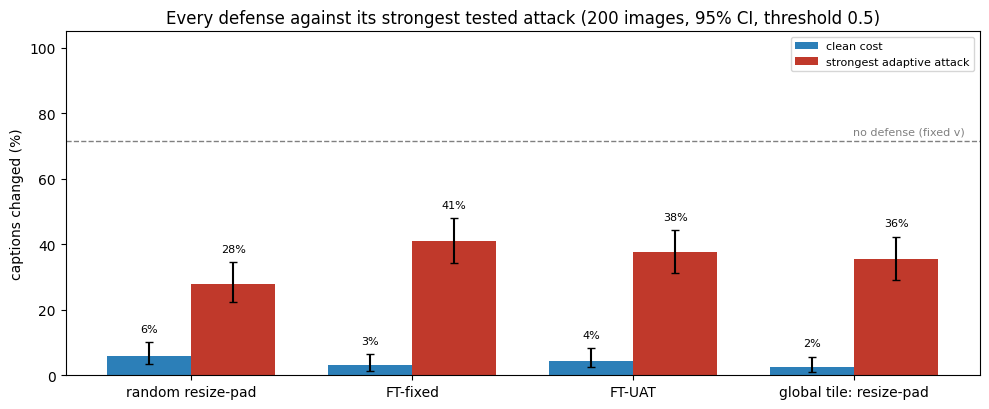

In [9]:
print(f"PART B — fine-tuned encoders, {N_EVAL} held-out images, splitting off")
for var in FT_PATHS: print(f"  {var}: clean-token cosine to the original encoder = {DRIFT[var]:.4f} (1.0 = unchanged)")
print()
rowsB = [("fixed v, original encoder (no defense)", CAPS["clean, original encoder"], CAPS["fixed v, no defense"])]
for var in FT_PATHS:
    rowsB += [(f"clean cost, {var}", CAPS["clean, original encoder"], CAPS[f"clean, {var}"]),
              (f"fixed v, {var}", CAPS[f"clean, {var}"], CAPS[f"fixed v, {var}"]),
              (f"ADAPTIVE v, {var}", CAPS[f"clean, {var}"], CAPS[f"adaptive v, {var}"])]
RES["B"] = rate_rows(rowsB); RES["drift"] = DRIFT
json.dump({"captions": CAPS, "results": RES}, open(RPATH, "w"), indent=1)

# one figure: every defense against its strongest tested attack (threshold 0.5)
summary = {"random resize-pad": (RES["A"]["clean cost of the defense"]["0.5"], RES["A"]["STRONG adaptive v, defended"]["0.5"])}
for var in FT_PATHS: summary[var] = (RES["B"][f"clean cost, {var}"]["0.5"], RES["B"][f"ADAPTIVE v, {var}"]["0.5"])
gt = OUT / "strong_adaptive_results.json"
if gt.exists():
    r = json.load(open(gt)).get("results", {})
    if "STRONG adaptive v, defended" in r:
        summary["global tile: resize-pad"] = (r["clean cost of the defense"], r["STRONG adaptive v, defended"])
names = list(summary); x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (lab, col) in enumerate([("clean cost", "#2c7fb8"), ("strongest adaptive attack", "#c0392b")]):
    vals = [100 * summary[n][k]["rate"] for n in names]
    err = np.array([[100 * (summary[n][k]["rate"] - summary[n][k]["ci95"][0]), 100 * (summary[n][k]["ci95"][1] - summary[n][k]["rate"])] for n in names]).T
    b = ax.bar(x + (k - .5) * w, vals, w, yerr=err, capsize=3, color=col, label=lab); ax.bar_label(b, fmt="%.0f%%", padding=6, fontsize=8)
ax.axhline(100 * RES["B"]["fixed v, original encoder (no defense)"]["0.5"]["rate"], ls="--", color="gray", lw=1)
ax.text(len(names) - .5, 100 * RES["B"]["fixed v, original encoder (no defense)"]["0.5"]["rate"] + 2, "no defense (fixed v)", ha="right", fontsize=8, color="gray")
ax.set_xticks(x, names); ax.set_ylim(0, 105); ax.set_ylabel("captions changed (%)"); ax.legend(fontsize=8)
ax.set_title(f"Every defense against its strongest tested attack ({N_EVAL} images, 95% CI, threshold 0.5)")
plt.tight_layout(); plt.savefig(OUT / "defense_ranking.png", dpi=150); plt.show()